In [1]:
import os, random, pickle, shutil
from collections import Counter, defaultdict

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

warnings.filterwarnings("ignore", message="Was asked to gather along dimension 0")

SEED        = 42
MODEL_NAME  = "bert-base-cased" # cased
MAX_LEN     = 256
EPOCHS      = 3
BATCH_SIZE  = 16
LR          = 5e-5
USE_CACHE   = True # True: dùng lại predictions.pkl / ner_model/ nếu đã có (không train lại)
RESULTS_CSV = "model_comparison.csv"   

OUT_DIR = "/kaggle/working/lab09" # Kaggle
# OUT_DIR = "."                     
os.makedirs(OUT_DIR, exist_ok=True)

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
print("device:", "cuda" if torch.cuda.is_available() else "cpu", "| OUT_DIR =", os.path.abspath(OUT_DIR))

device: cuda | OUT_DIR = /kaggle/working/lab09


In [2]:
def get_entities(seq):
    # list nhãn BIO của một câu -> list (type, start, end), end inclusive
    out, cur = [], None
    for i, lab in enumerate(seq):
        if lab == "O":
            if cur: out.append(tuple(cur)); cur = None
            continue
        pre, t = lab.split("-", 1)
        if pre == "B" or cur is None or cur[0] != t:
            if cur: out.append(tuple(cur))
            cur = [t, i, i]
        else:
            cur[2] = i
    if cur: out.append(tuple(cur))
    return out

def _counts(golds, preds):
    tp = fp = fn = 0
    for g, p in zip(golds, preds):
        G, P = set(get_entities(g)), set(get_entities(p))
        tp += len(G & P); fp += len(P - G); fn += len(G - P)
    return tp, fp, fn

def precision_score(golds, preds):
    tp, fp, fn = _counts(golds, preds); return tp / (tp + fp) if tp + fp else 0.0

def recall_score(golds, preds):
    tp, fp, fn = _counts(golds, preds); return tp / (tp + fn) if tp + fn else 0.0

def f1_score(golds, preds):
    p, r = precision_score(golds, preds), recall_score(golds, preds)
    return 2 * p * r / (p + r) if p + r else 0.0

def accuracy_score(golds, preds):
    # token accuracy (gồm cả nhãn O)
    yt = [t for s in golds for t in s]; yp = [t for s in preds for t in s]
    return sum(a == b for a, b in zip(yt, yp)) / len(yt)

In [3]:
import glob
from datasets import Dataset, DatasetDict

# Thứ tự nhãn chuẩn của CoNLL-2003 trong HuggingFace (ner_tags lưu dạng số nguyên theo thứ tự này)
label_list = ["O", "B-PER", "I-PER", "B-ORG", "I-ORG", "B-LOC", "I-LOC", "B-MISC", "I-MISC"]
label2id   = {l: i for i, l in enumerate(label_list)}
id2label   = {i: l for l, i in label2id.items()}

def find_parquet(split):
    hits = glob.glob(f"/kaggle/input/**/conll2003-{split}.parquet", recursive=True) \
        + glob.glob(f"**/conll2003-{split}.parquet", recursive=True)
    if not hits:
        raise FileNotFoundError(f"Không thấy conll2003-{split}.parquet — kiểm tra phần Input của notebook.")
    return hits[0]

def read_split(split):
    path = find_parquet(split)
    df = pd.read_parquet(path)
    tok_col = next(c for c in ["tokens", "words"] if c in df.columns)
    tag_col = next(c for c in ["ner_tags", "ner", "labels"] if c in df.columns)
    to_id = lambda x: label2id[x] if isinstance(x, str) else int(x)
    print(f"{split:11s} {path}  columns={list(df.columns)}  rows={len(df)}")
    return Dataset.from_dict({"tokens": [[str(w) for w in t] for t in df[tok_col]],
                              "ner_tags": [[to_id(x) for x in t] for t in df[tag_col]]})

raw = DatasetDict({sp: read_split(sp) for sp in ["train", "validation", "test"]})
print(label_list)

def to_names(ds):
    return [[label_list[t] for t in tags] for tags in ds["ner_tags"]]

# list(...) bắt buộc: datasets mới trả về đối tượng Column, tokenizer chỉ nhận list[list[str]]
as_lists = lambda col: [list(x) for x in col]
train_tokens, train_tags = as_lists(raw["train"]["tokens"]), to_names(raw["train"])
val_tokens,   val_tags   = as_lists(raw["validation"]["tokens"]), to_names(raw["validation"])
test_tokens,  gold       = as_lists(raw["test"]["tokens"]), to_names(raw["test"]) # gold = nhãn BIO mức word của test set
print("train/val/test:", len(train_tokens), len(val_tokens), len(test_tokens))

train       /kaggle/input/datasets/valphlien/conll2003/conll2003-train.parquet  columns=['id', 'tokens', 'pos_tags', 'chunk_tags', 'ner_tags']  rows=14041
validation  /kaggle/input/datasets/valphlien/conll2003/conll2003-validation.parquet  columns=['id', 'tokens', 'pos_tags', 'chunk_tags', 'ner_tags']  rows=3250
test        /kaggle/input/datasets/valphlien/conll2003/conll2003-test.parquet  columns=['id', 'tokens', 'pos_tags', 'chunk_tags', 'ner_tags']  rows=3453
['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC', 'B-MISC', 'I-MISC']
train/val/test: 14041 3250 3453


### Baseline - word features + linear classifier
Mỗi word → vector đặc trưng thưa (từ, hậu tố/tiền tố, shape, từ trước/sau) → Logistic Regression (SGD).
Baseline không có contextual representation từ pretraining; chỉ nhìn cửa sổ ±1 word.

In [4]:
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import SGDClassifier

def word_feats(sent, i):
    w = sent[i]
    f = {
        "bias": 1.0, "w.lower": w.lower(), "w[-3:]": w[-3:], "w[-2:]": w[-2:], "w[:3]": w[:3],
        "w.isupper": w.isupper(), "w.istitle": w.istitle(), "w.isdigit": w.isdigit(),
        "w.hasdigit": any(c.isdigit() for c in w), "w.hashyphen": "-" in w, "w.len": min(len(w), 10),
    }
    if i > 0:
        p = sent[i-1]; f.update({"-1.lower": p.lower(), "-1.istitle": p.istitle(), "-1.isupper": p.isupper()})
    else:
        f["BOS"] = True
    if i < len(sent) - 1:
        n = sent[i+1]; f.update({"+1.lower": n.lower(), "+1.istitle": n.istitle(), "+1.isupper": n.isupper()})
    else:
        f["EOS"] = True
    return f

def featurize(sents):
    return [word_feats(s, i) for s in sents for i in range(len(s))]

dv = DictVectorizer()
X_train = dv.fit_transform(featurize(train_tokens))
y_train = [t for s in train_tags for t in s]
print("X_train:", X_train.shape)

clf = SGDClassifier(loss="log_loss", alpha=1e-5, max_iter=100, tol=1e-3, random_state=SEED, n_jobs=-1)
from sklearn.exceptions import ConvergenceWarning
with warnings.catch_warnings():
    warnings.simplefilter("ignore", ConvergenceWarning) 
    clf.fit(X_train, y_train)

def predict_baseline(sents):
    flat = clf.predict(dv.transform(featurize(sents)))
    out, k = [], 0
    for s in sents:
        out.append(list(flat[k:k+len(s)])); k += len(s)
    return out

pred_base = predict_baseline(test_tokens)
assert all(len(a) == len(b) for a, b in zip(gold, pred_base))

X_train: (203621, 74326)


### 4. Pretrained Transformer - token classification
Label alignment: Strategy A — gán nhãn word cho *subword đầu tiên*, các subword còn lại và token đặc biệt = `-100` (IGNORE, không vào loss).

In [5]:
from transformers import (AutoTokenizer, AutoModelForTokenClassification,
                          DataCollatorForTokenClassification, TrainingArguments, Trainer)
from datasets import Dataset

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def tokenize_and_align(batch):
    enc = tokenizer(batch["tokens"], is_split_into_words=True, truncation=True, max_length=MAX_LEN)
    all_labels = []
    for i, tags in enumerate(batch["ner_tags"]):
        prev, labels = None, []
        for w in enc.word_ids(batch_index=i):
            if w is None:        labels.append(-100)       # [CLS], [SEP]
            elif w != prev:      labels.append(tags[w])    # subword đầu của word
            else:                labels.append(-100)       # subword tiếp theo -> IGNORE
            prev = w
        all_labels.append(labels)
    enc["labels"] = all_labels
    return enc

tok = raw.map(tokenize_and_align, batched=True, remove_columns=raw["train"].column_names)

# Nhìn tận mắt: tokens / input_ids / word_ids / labels của 1 câu
ex  = raw["train"][0]
enc = tokenizer(ex["tokens"], is_split_into_words=True)
print(pd.DataFrame({
    "token": tokenizer.convert_ids_to_tokens(enc["input_ids"]),
    "input_id": enc["input_ids"],
    "word_id": enc.word_ids(),
    "label": [(-100 if l is None else l) for l in tok["train"][0]["labels"]],
}))

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/213k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/436k [00:00<?, ?B/s]

Map:   0%|          | 0/14041 [00:00<?, ? examples/s]

Map:   0%|          | 0/3250 [00:00<?, ? examples/s]

Map:   0%|          | 0/3453 [00:00<?, ? examples/s]

      token  input_id  word_id  label
0     [CLS]       101      NaN   -100
1        EU      7270      0.0      3
2   rejects     22961      1.0      0
3    German      1528      2.0      7
4      call      1840      3.0      0
5        to      1106      4.0      0
6   boycott     21423      5.0      0
7   British      1418      6.0      7
8        la      2495      7.0      0
9      ##mb     12913      7.0   -100
10        .       119      8.0      0
11    [SEP]       102      NaN   -100


In [6]:
def compute_metrics(p):
    preds = np.argmax(p.predictions, -1)
    P, G = [], []
    for pr, lb in zip(preds, p.label_ids):
        P.append([label_list[a] for a, b in zip(pr, lb) if b != -100])
        G.append([label_list[b] for a, b in zip(pr, lb) if b != -100])
    return {"precision": precision_score(G, P), "recall": recall_score(G, P),
            "f1": f1_score(G, P), "accuracy": accuracy_score(G, P)}

CACHE = os.path.join(OUT_DIR, "predictions.pkl")

MODEL_DIR = os.path.join(OUT_DIR, "ner_model")

if USE_CACHE and os.path.exists(CACHE):
    with open(CACHE, "rb") as f:
        pred_bert = pickle.load(f)["pred_bert"]
    print("loaded cached predictions")
else:
    resume = USE_CACHE and os.path.exists(os.path.join(MODEL_DIR, "config.json"))
    if resume:      # đã train xong lần trước (ner_model/ có sẵn) -> chỉ cần predict lại, không train lại
        print("found saved model -> skip training:", MODEL_DIR)
        model = AutoModelForTokenClassification.from_pretrained(MODEL_DIR)
    else:
        model = AutoModelForTokenClassification.from_pretrained(
            MODEL_NAME, num_labels=len(label_list), id2label=id2label, label2id=label2id)

    ta_kwargs = dict(output_dir=os.path.join(OUT_DIR, "ckpt"), learning_rate=LR,
                     per_device_train_batch_size=BATCH_SIZE, per_device_eval_batch_size=64,
                     num_train_epochs=EPOCHS, weight_decay=0.01, save_strategy="no",
                     fp16=torch.cuda.is_available(), report_to="none", seed=SEED, logging_steps=200)
    try:
        args = TrainingArguments(eval_strategy="epoch", **ta_kwargs)
    except TypeError:                       # transformers cũ
        args = TrainingArguments(evaluation_strategy="epoch", **ta_kwargs)

    tr_kwargs = dict(model=model, args=args, train_dataset=tok["train"], eval_dataset=tok["validation"],
                     data_collator=DataCollatorForTokenClassification(tokenizer),
                     compute_metrics=compute_metrics)
    try:
        trainer = Trainer(processing_class=tokenizer, **tr_kwargs)
    except TypeError:
        trainer = Trainer(tokenizer=tokenizer, **tr_kwargs)

    if not resume:
        trainer.train()
        # lưu model trước khi predict (nếu predict lỗi thì không mất công train)
        trainer.save_model(MODEL_DIR)
        tokenizer.save_pretrained(MODEL_DIR)

    # ---- predict test, quy về mức word (subword đầu tiên) ----
    out = trainer.predict(tok["test"])
    pred_ids = out.predictions.argmax(-1)
    word_enc = tokenizer(test_tokens, is_split_into_words=True, truncation=True, max_length=MAX_LEN)
    pred_bert = []
    for i, words in enumerate(test_tokens):
        wp, prev = ["O"] * len(words), None
        for pos, w in enumerate(word_enc.word_ids(batch_index=i)):
            if w is not None and w != prev:
                wp[w] = label_list[pred_ids[i][pos]]
            prev = w
        pred_bert.append(wp)
    with open(CACHE, "wb") as f:
        pickle.dump({"pred_bert": pred_bert}, f)

assert all(len(a) == len(b) for a, b in zip(gold, pred_bert))
print("test sentences:", len(gold))

model.safetensors: reconstructing file:   0%|          |  0.00B /  436MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertForTokenClassification LOAD REPORT from: bert-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
bert.pooler.dense.bias                     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
bert.pooler.dense.weight                   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly i

Epoch,Training Loss,Validation Loss,Precision,Recall,F1,Accuracy
1,0.103435,0.078104,0.924553,0.932178,0.928350,0.988299
2,0.045909,0.076058,0.939916,0.945136,0.942519,0.990324
3,0.018398,0.073662,0.944342,0.950858,0.947589,0.991297


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

test sentences: 3453


## 18. Experiment 2 - Baseline vs Transformer

In [7]:
from sklearn.metrics import precision_recall_fscore_support, confusion_matrix

ENT_LABELS = [l for l in label_list if l != "O"]

def entity_level(golds, preds):
    return dict(Precision=precision_score(golds, preds), Recall=recall_score(golds, preds), F1=f1_score(golds, preds))

def token_level(golds, preds):
    yt = [t for s in golds for t in s]; yp = [t for s in preds for t in s]
    p, r, f, _ = precision_recall_fscore_support(yt, yp, labels=ENT_LABELS, average="micro", zero_division=0)
    return dict(Precision=p, Recall=r, F1=f, Accuracy=accuracy_score(golds, preds))

rows = []
for name, preds in [("Baseline", pred_base), ("Pretrained Transformer", pred_bert)]:
    rows.append({"Model": name, "Level": "entity", **entity_level(gold, preds), "Accuracy": np.nan})
    rows.append({"Model": name, "Level": "token (non-O)", **token_level(gold, preds)})

results = pd.DataFrame(rows)
results.to_csv(os.path.join(OUT_DIR, RESULTS_CSV), index=False)
results.round(4)

,Model,Level,Precision,Recall,F1,Accuracy
0,Baseline,entity,0.7010,0.7261,0.7133,NaN
1,Baseline,token (non-O),0.7925,0.7589,0.7753,0.9495
2,Pretrained Transformer,entity,0.9010,0.9180,0.9094,NaN
3,Pretrained Transformer,token (non-O),0.9154,0.9312,0.9232,0.9822


## 19. Experiment 3 - Token-level vs Entity-level

In [8]:
def spans(seq):
    # tập các entity (type, start, end) của một câu, end inclusive
    return {(t, s, e) for t, s, e in get_entities(seq)}

g, p = ["B-LOC", "I-LOC"], ["B-LOC", "O"]
print("token đúng:", sum(a == b for a, b in zip(g, p)), "/", len(g))
G, P = spans(g), spans(p)
print("gold entities:", G, "| pred entities:", P)
print("entity TP/FP/FN:", len(G & P), len(P - G), len(G - P))

token đúng: 1 / 2
gold entities: {('LOC', 0, 1)} | pred entities: {('LOC', 0, 0)}
entity TP/FP/FN: 0 1 1


In [9]:
# Trên test set thật: token accuracy vs entity F1, và tỉ lệ entity "đúng một phần"
def partial_stats(golds, preds):
    exact = partial = missed = 0
    for g, p in zip(golds, preds):
        G, P = spans(g), spans(p)
        for gs in G:
            if gs in P: exact += 1
            elif any(not (gs[2] < ps[1] or ps[2] < gs[1]) for ps in P): partial += 1   # overlap nhưng không khớp
            else: missed += 1
    n = exact + partial + missed
    return dict(gold_entities=n, exact=exact, overlap_not_exact=partial, no_overlap=missed,
                exact_rate=exact / n, overlap_not_exact_rate=partial / n)

cmp = pd.DataFrame({
    "Baseline": {"token accuracy": accuracy_score(gold, pred_base), "entity F1": f1_score(gold, pred_base), **partial_stats(gold, pred_base)},
    "Transformer": {"token accuracy": accuracy_score(gold, pred_bert), "entity F1": f1_score(gold, pred_bert), **partial_stats(gold, pred_bert)},
})
cmp.round(4)

,Baseline,Transformer
token accuracy,0.9495,0.9822
entity F1,0.7133,0.9094
gold_entities,5648.0000,5648.0000
exact,4101.0000,5185.0000
overlap_not_exact,1064.0000,391.0000
no_overlap,483.0000,72.0000
exact_rate,0.7261,0.9180
overlap_not_exact_rate,0.1884,0.0692


## 20. Precision / Recall / F1 ở entity level

In [10]:
def prf(tp, fp, fn):
    P = tp / (tp + fp) if tp + fp else 0.0
    R = tp / (tp + fn) if tp + fn else 0.0
    F = 2 * P * R / (P + R) if P + R else 0.0
    return P, R, F

def entity_prf(golds, preds, etype=None):
    tp = fp = fn = 0
    for g, p in zip(golds, preds):
        G, P = spans(g), spans(p)
        if etype: G = {x for x in G if x[0] == etype}; P = {x for x in P if x[0] == etype}
        tp += len(G & P); fp += len(P - G); fn += len(G - P)
    return tp, fp, fn

for name, preds in [("Baseline", pred_base), ("Transformer", pred_bert)]:
    tp, fp, fn = entity_prf(gold, preds)
    P, R, F = prf(tp, fp, fn)
    print(f"{name:12s} TP={tp} FP={fp} FN={fn} | P={P:.4f} R={R:.4f} F1={F:.4f} "
          f"| fn kiểm chứng: P={precision_score(gold, preds):.4f} R={recall_score(gold, preds):.4f} F1={f1_score(gold, preds):.4f}")
    assert abs(F - f1_score(gold, preds)) < 1e-9      # khớp hàm f1_score ở trên
    try:                                              # đối chiếu thêm với seqeval nếu môi trường có
        from seqeval.metrics import f1_score as sq_f1
        assert abs(F - sq_f1(gold, preds)) < 1e-6
        print("   (đã đối chiếu seqeval: khớp)")
    except ImportError:
        pass

Baseline     TP=4101 FP=1749 FN=1547 | P=0.7010 R=0.7261 F1=0.7133 | fn kiểm chứng: P=0.7010 R=0.7261 F1=0.7133
Transformer  TP=5185 FP=570 FN=463 | P=0.9010 R=0.9180 F1=0.9094 | fn kiểm chứng: P=0.9010 R=0.9180 F1=0.9094


## 21. Experiment 4 - Entity type analysis

In [11]:
train_ent_count = Counter(t for s in train_tags for (t, _, _) in get_entities(s))

rows = []
for name, preds in [("Baseline", pred_base), ("Pretrained Transformer", pred_bert)]:
    for et in ["PER", "ORG", "LOC", "MISC"]:
        tp, fp, fn = entity_prf(gold, preds, et)
        P, R, F = prf(tp, fp, fn)
        rows.append({"Model": name, "Entity": et, "Precision": P, "Recall": R, "F1": F,
                     "Support": tp + fn, "Train_entities": train_ent_count[et]})
    tp, fp, fn = entity_prf(gold, preds)
    P, R, F = prf(tp, fp, fn)
    rows.append({"Model": name, "Entity": "ALL (micro)", "Precision": P, "Recall": R, "F1": F,
                 "Support": tp + fn, "Train_entities": sum(train_ent_count.values())})

entity_metrics = pd.DataFrame(rows)
entity_metrics.to_csv(os.path.join(OUT_DIR, "entity_metrics.csv"), index=False)
entity_metrics.round(4)

,Model,Entity,Precision,Recall,F1,Support,Train_entities
0,Baseline,PER,0.6914,0.8009,0.7421,1617,6600
1,Baseline,ORG,0.6025,0.6033,0.6029,1661,6321
2,Baseline,LOC,0.7953,0.7872,0.7912,1668,7140
3,Baseline,MISC,0.7406,0.6994,0.7194,702,3438
4,Baseline,ALL (micro),0.7010,0.7261,0.7133,5648,23499
5,Pretrained Transformer,PER,0.9620,0.9542,0.9581,1617,6600
6,Pretrained Transformer,ORG,0.8760,0.9061,0.8908,1661,6321
7,Pretrained Transformer,LOC,0.9213,0.9341,0.9277,1668,7140
8,Pretrained Transformer,MISC,0.7803,0.8248,0.8019,702,3438
9,Pretrained Transformer,ALL (micro),0.9010,0.9180,0.9094,5648,23499


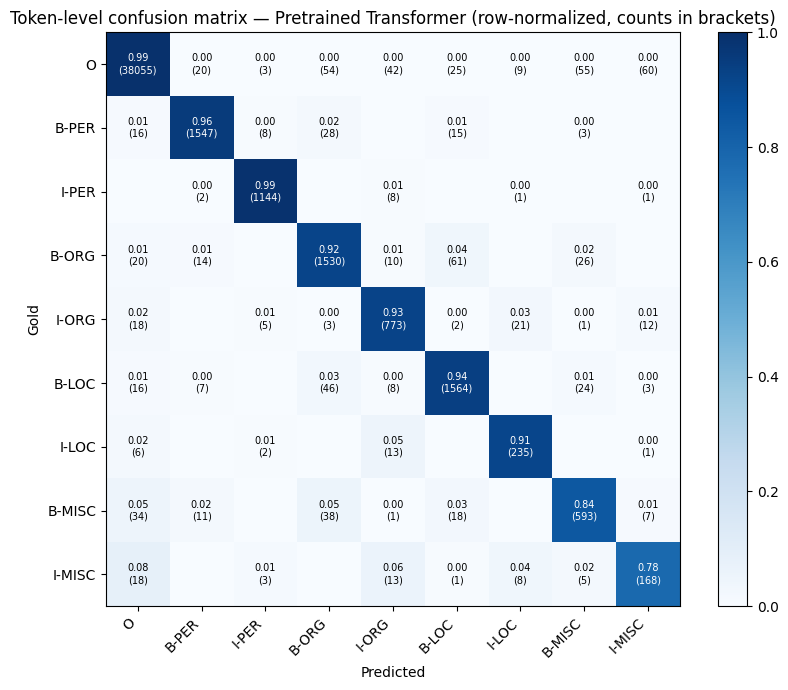

In [12]:
# Confusion matrix mức token (BIO, 9 nhãn) của Transformer - chuẩn hoá theo hàng (recall mỗi nhãn)
yt = [t for s in gold for t in s]; yp = [t for s in pred_bert for t in s]
cm  = confusion_matrix(yt, yp, labels=label_list)
cmn = cm / cm.sum(axis=1, keepdims=True).clip(min=1)

fig, ax = plt.subplots(figsize=(8.5, 7))
im = ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(label_list))); ax.set_xticklabels(label_list, rotation=45, ha="right")
ax.set_yticks(range(len(label_list))); ax.set_yticklabels(label_list)
for i in range(len(label_list)):
    for j in range(len(label_list)):
        if cm[i, j] > 0:
            ax.text(j, i, f"{cmn[i, j]:.2f}\n({cm[i, j]})", ha="center", va="center", fontsize=7,
                    color="white" if cmn[i, j] > 0.5 else "black")
ax.set_xlabel("Predicted"); ax.set_ylabel("Gold")
ax.set_title("Token-level confusion matrix — Pretrained Transformer (row-normalized, counts in brackets)")
fig.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "confusion_matrix.png"), dpi=150)
plt.show()

## 22. Experiment 5 - Entity length

In [13]:
def bucket(n): return "1" if n == 1 else "2" if n == 2 else "3" if n == 3 else "4+"
BUCKETS = ["1", "2", "3", "4+"]

def prf_by_length(golds, preds):
    tp, fp, fn = Counter(), Counter(), Counter()
    for g, p in zip(golds, preds):
        G, P = spans(g), spans(p)
        for t, s, e in G & P: tp[bucket(e - s + 1)] += 1
        for t, s, e in P - G: fp[bucket(e - s + 1)] += 1
        for t, s, e in G - P: fn[bucket(e - s + 1)] += 1
    out = {}
    for b in BUCKETS:
        P_, R_, F_ = prf(tp[b], fp[b], fn[b])
        out[b] = dict(Precision=P_, Recall=R_, F1=F_, Support=tp[b] + fn[b])
    return out

len_rows = []
for name, preds in [("Baseline", pred_base), ("Pretrained Transformer", pred_bert)]:
    for b, d in prf_by_length(gold, preds).items():
        len_rows.append({"Model": name, "Entity length": b, **d})
len_df = pd.DataFrame(len_rows)
len_df.to_csv(os.path.join(OUT_DIR, "entity_length_metrics.csv"), index=False)   # file phụ, kèm số liệu cho báo cáo
len_df.round(4)

,Model,Entity length,Precision,Recall,F1,Support
0,Baseline,1,0.6455,0.7406,0.6898,3574
1,Baseline,2,0.8384,0.7539,0.7940,1776
2,Baseline,3,0.7842,0.4619,0.5813,236
3,Baseline,4+,0.4615,0.0968,0.1600,62
4,Pretrained Transformer,1,0.8942,0.9177,0.9058,3574
5,Pretrained Transformer,2,0.9240,0.9245,0.9243,1776
6,Pretrained Transformer,3,0.8583,0.8729,0.8655,236
7,Pretrained Transformer,4+,0.8143,0.9194,0.8636,62


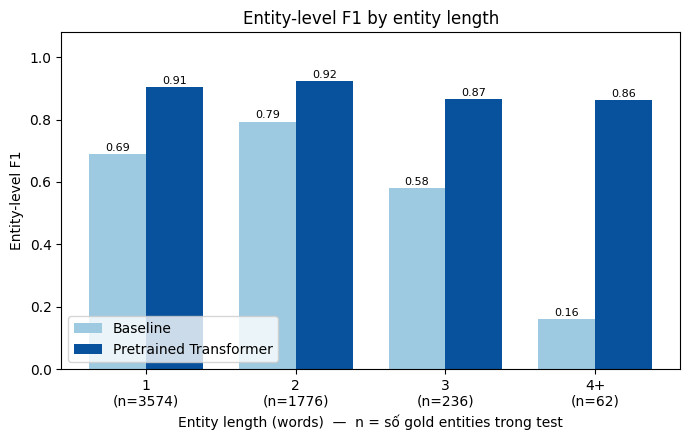

In [14]:
fig, ax = plt.subplots(figsize=(7, 4.5))
w = 0.38; x = np.arange(len(BUCKETS))
for k, (name, color) in enumerate([("Baseline", "#9ecae1"), ("Pretrained Transformer", "#08519c")]):
    f1s = [len_df[(len_df.Model == name) & (len_df["Entity length"] == b)].F1.iloc[0] for b in BUCKETS]
    bars = ax.bar(x + (k - 0.5) * w, f1s, w, label=name, color=color)
    for bar, v in zip(bars, f1s):
        ax.text(bar.get_x() + bar.get_width() / 2, v + 0.01, f"{v:.2f}", ha="center", fontsize=8)
sup = [len_df[(len_df.Model == "Pretrained Transformer") & (len_df["Entity length"] == b)].Support.iloc[0] for b in BUCKETS]
ax.set_xticks(x); ax.set_xticklabels([f"{b}\n(n={s})" for b, s in zip(BUCKETS, sup)])
ax.set_xlabel("Entity length (words)  —  n = số gold entities trong test"); ax.set_ylabel("Entity-level F1")
ax.set_ylim(0, 1.08); ax.set_title("Entity-level F1 by entity length"); ax.legend(loc="lower left")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "entity_length_analysis.png"), dpi=150)
plt.show()

## 23. Experiment 6 - Error analysis

In [15]:
def overlap(a, b): return not (a[2] < b[1] or b[2] < a[1])

def span_text(words, sp): return f"[{sp[0]}] " + " ".join(words[sp[1]: sp[2] + 1])

train_surface = Counter(" ".join(toks[s:e + 1]) for toks, tags in zip(train_tokens, train_tags)
                        for (_, s, e) in get_entities(tags))

_sub_cache = {}
def n_sub(w):
    if w not in _sub_cache: _sub_cache[w] = len(tokenizer.tokenize(w))
    return _sub_cache[w]

def collect_errors(tokens_list, golds, preds):
    errs = []
    for sid, (words, g, p) in enumerate(zip(tokens_list, golds, preds)):
        G, P = spans(g), spans(p)
        for gs in G - P:
            ov = [ps for ps in P if overlap(gs, ps)]
            if not ov:
                errs.append((sid, "false negative (missing entity)", gs, None))
            for ps in ov:
                if (gs[1], gs[2]) == (ps[1], ps[2]):
                    errs.append((sid, "wrong entity type", gs, ps))
                else:
                    kind = "boundary error (same type)" if gs[0] == ps[0] else "boundary error + wrong type"
                    errs.append((sid, kind, gs, ps))
        for ps in P - G:
            if not any(overlap(ps, gs) for gs in G):
                errs.append((sid, "false positive (spurious entity)", None, ps))
    return errs

errors = collect_errors(test_tokens, gold, pred_bert)
err_counts = Counter(e[1] for e in errors)
pd.Series(err_counts, name="count").sort_values(ascending=False).to_frame()

,count
wrong entity type,226
false positive (spurious entity),162
boundary error (same type),113
boundary error + wrong type,93
false negative (missing entity),72


In [16]:
def group_of(kind):
    if kind.startswith("false positive"): return "FP"
    if kind.startswith("false negative"): return "FN"
    if kind.startswith("boundary"):       return "BOUNDARY"
    return "TYPE"

N_PER_GROUP = 8      # lấy dư 8 ứng viên mỗi nhóm; em chọn ra tối thiểu 5 ví dụ tiêu biểu cho mỗi nhóm
rng = random.Random(SEED)
rows = []
for grp in ["FP", "FN", "BOUNDARY"]:
    pool = [e for e in errors if group_of(e[1]) == grp]
    for sid, kind, gs, ps in rng.sample(pool, min(N_PER_GROUP, len(pool))):
        words = test_tokens[sid]
        idx = [i for sp in (gs, ps) if sp for i in range(sp[1], sp[2] + 1)]
        surf = " ".join(words[(gs or ps)[1]: (gs or ps)[2] + 1])
        rows.append({
            "Group": grp, "sent_id": sid, "Text": " ".join(words),
            "Gold": span_text(words, gs) if gs else "(none)",
            "Prediction": span_text(words, ps) if ps else "(none)",
            "Error type (gợi ý)": kind,
            "has_subword_split": any(n_sub(words[i]) > 1 for i in idx),
            "train_freq": train_surface[surf],
            "Explanation": "",                   
        })

err_df = pd.DataFrame(rows)
err_df.to_csv(os.path.join(OUT_DIR, "error_analysis_candidates.csv"), index=False)
pd.set_option("display.max_colwidth", 90, "display.width", 250)
err_df

,Group,sent_id,Text,Gold,Prediction,Error type (gợi ý),has_subword_split,train_freq,Explanation
0,FP,514,W L T PF PA,(none),[LOC] PA,false positive (spurious entity),False,1,
1,FP,352,Contractors won 4-0 on aggregate .,(none),[ORG] Contractors,false positive (spurious entity),True,0,
2,FP,1474,East Timorese Roman Catholic Bishop Carlos Belo left Dili on Friday on his way to Norw...,(none),[MISC] 1996,false positive (spurious entity),False,0,
3,FP,1432,Wheat 121 130 121.3 121,(none),[PER] Wheat,false positive (spurious entity),True,0,
4,FP,1293,Polish ex-communist president to visit Pope .,(none),[PER] Pope,false positive (spurious entity),False,0,
5,FP,635,"RKC Waalwijk 1 ( Starbuck 76 ) Willem II Tilburg 2 ( Konterman 45 ,",(none),[PER] Starbuck,false positive (spurious entity),True,0,
6,FP,512,NATIONAL FOOTBALL CONFERENCE,(none),[MISC] NATIONAL,false positive (spurious entity),True,0,
7,FP,2388,Profile of the winner of Saturday 's women 's World Cup super G race :,(none),[MISC] G,false positive (spurious entity),False,0,
8,FN,408,League games on Thursday ( home team in CAPS ) :,[ORG] League,(none),false negative (missing entity),False,0,
9,FN,2350,In a stand some analysts linked to controversy over Singapore 's caning of an American...,[MISC] then-U.S.,(none),false negative (missing entity),True,0,


In [17]:
lines = ["# Error Analysis — Pretrained Transformer (CoNLL-2003 test)", "",
         "| Text | Gold | Prediction | Error type | Explanation |", "|---|---|---|---|---|"]
for r in err_df.to_dict("records"):
    lines.append(f"| {r['Text']} | {r['Gold']} | {r['Prediction']} | {r['Error type (gợi ý)']} | _()_ |")
with open(os.path.join(OUT_DIR, "error_analysis.md"), "w", encoding="utf-8") as f:
    f.write("\n".join(lines) + "\n")
print("saved error_analysis.md (khung)")

saved error_analysis.md (khung)


## 24. Context analysis - same surface form → different entity type

In [18]:
surface_types = defaultdict(Counter)
occ = defaultdict(list)  # (surface, type) -> list[(sent_id, span)]
for sid, (words, g) in enumerate(zip(test_tokens, gold)):
    for (t, s, e) in get_entities(g):
        surf = " ".join(words[s:e + 1])
        surface_types[surf][t] += 1
        occ[(surf, t)].append((sid, (t, s, e)))

ambiguous = {s: c for s, c in surface_types.items() if len(c) >= 2}
amb_df = (pd.DataFrame([{"surface": s, "types": dict(c), "total": sum(c.values())} for s, c in ambiguous.items()])
          .sort_values("total", ascending=False).reset_index(drop=True))
print("số surface form đa-type trong test:", len(amb_df))
amb_df.head(15)

số surface form đa-type trong test: 64


,surface,types,total
0,Barcelona,"{'LOC': 2, 'ORG': 22}",24
1,NEW YORK,"{'LOC': 19, 'ORG': 3}",22
2,Santa Fe,"{'LOC': 2, 'ORG': 16}",18
3,CHICAGO,"{'ORG': 7, 'LOC': 6}",13
4,WASHINGTON,"{'ORG': 8, 'LOC': 4}",12
5,American,"{'MISC': 6, 'ORG': 4}",10
6,DETROIT,"{'ORG': 7, 'LOC': 2}",9
7,DALLAS,"{'ORG': 6, 'LOC': 3}",9
8,New York,"{'LOC': 8, 'ORG': 1}",9
9,Busang,"{'ORG': 4, 'LOC': 5}",9


In [19]:
def pred_at(words, pseq, start):
    for (t, a, b) in get_entities(pseq):
        if a <= start <= b:
            return f"{t}: " + " ".join(words[a:b + 1])
    return "O"

def context_snip(words, s, e, k=7):
    lo, hi = max(0, s - k), min(len(words), e + 1 + k)
    return ("… " if lo else "") + " ".join(words[lo:hi]) + (" …" if hi < len(words) else "")

ctx_rows = []
for surf in amb_df.surface.head(6):
    for et in surface_types[surf]:
        sid, (t, s, e) = occ[(surf, et)][0]          # lấy ví dụ đầu tiên của mỗi type
        words = test_tokens[sid]
        ctx_rows.append({"surface": surf, "gold_type": et, "context": context_snip(words, s, e),
                         "baseline_pred": pred_at(words, pred_base[sid], s),
                         "transformer_pred": pred_at(words, pred_bert[sid], s), "sent_id": sid})
ctx_df = pd.DataFrame(ctx_rows)
ctx_df

,surface,gold_type,context,baseline_pred,transformer_pred,sent_id
0,Barcelona,LOC,"… players ' status committee , meeting in Barcelona , decided that although the Udines...",LOC: Barcelona,LOC: Barcelona,146
1,Barcelona,ORG,Barcelona ( Spain ) 9 4 5 13,ORG: Barcelona,ORG: Barcelona,179
2,NEW YORK,LOC,NEW YORK 1996-12-06,LOC: NEW YORK,LOC: NEW YORK,354
3,NEW YORK,ORG,NEW YORK 10 6 .625 3,LOC: NEW YORK,ORG: NEW YORK,440
4,Santa Fe,LOC,Wall St speculates about Santa Fe savior .,PER: Santa Fe,LOC: Santa Fe,1150
5,Santa Fe,ORG,… for Santa Fe Pacific Gold Corp if Santa Fe rejects unsolicited suitor Newmont Mining...,PER: Santa Fe,ORG: Santa Fe,1153
6,CHICAGO,ORG,CHICAGO 12 12 3 71 67 27,ORG: CHICAGO,ORG: CHICAGO,381
7,CHICAGO,LOC,MONTREAL AT CHICAGO,LOC: CHICAGO,LOC: CHICAGO,398
8,WASHINGTON,ORG,WASHINGTON 13 12 1 69 66 27,LOC: WASHINGTON,ORG: WASHINGTON,372
9,WASHINGTON,LOC,PITTSBURGH AT WASHINGTON,LOC: WASHINGTON,LOC: WASHINGTON,397


In [20]:
# Tổng hợp file 
produced = [RESULTS_CSV, "entity_metrics.csv", "entity_length_analysis.png", "confusion_matrix.png",
            "entity_length_metrics.csv", "error_analysis_candidates.csv", "error_analysis.md"]
for f in produced:
    path = os.path.join(OUT_DIR, f)
    print(("OK      " if os.path.exists(path) else "MISSING ") + f)
print("model:", os.path.exists(os.path.join(OUT_DIR, "ner_model")))

OK      model_comparison.csv
OK      entity_metrics.csv
OK      entity_length_analysis.png
OK      confusion_matrix.png
OK      entity_length_metrics.csv
OK      error_analysis_candidates.csv
OK      error_analysis.md
model: True


In [21]:
trainer.save_model("/kaggle/working/ner_model")          # hoặc model.save_pretrained(...)
tokenizer.save_pretrained("/kaggle/working/ner_model")   # bắt buộc lưu cả tokenizer

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('/kaggle/working/ner_model/tokenizer_config.json',
 '/kaggle/working/ner_model/tokenizer.json')

In [22]:
import shutil
shutil.make_archive("/kaggle/working/ner_model", "zip", "/kaggle/working/ner_model")

'/kaggle/working/ner_model.zip'

In [23]:
from IPython.display import FileLink
FileLink("ner_model.zip")

/kaggle/working/ner_model.zip